In [57]:
#IMPORTS

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from scipy.signal import peak_widths

In [58]:
CALIBRATION_DIR = Path("Calibration")
MEASUREMENTS_DIR = Path("Metal measurements")

folders = {"calibration": CALIBRATION_DIR, "measurements": MEASUREMENTS_DIR}
groups = ["Experiment", "Data", "Instruments"]

In [59]:
#LOADING DATA, FINDING IMPORTANT PEAKS

data = {}
for name, folder in folders.items():
    data[name] = {}
    for f in sorted(folder.glob("*.nc")):
        if name == "calibration":
            key = f.stem
        else:
            parts = f.stem.split("_")
            key = f"week{parts[1]}_metal_{parts[3]}"

        if f in data[name]:
            print(f"Warning: key '{key}' already used in {name}, skipping {f.name}")
            continue
        if f.stat().st_size == 0:
            print(f"Warning: {f.name} is empty, skipping")
            continue
        else:
            print(f"Loading {f.name}, filesize: {f.stat().st_size}")
        
        with xr.open_dataset(f, group="Data", mask_and_scale=False) as ds:
            counts = ds["MCA"].values #(1, 8000), uint32
        spectrum = counts[0].astype(float) #float avoids uint32 wraparound
        channels = np.arange(len(spectrum))
        entry = {"counts": counts, "spectrum": spectrum, "channels": channels}
        data[name][key] = entry

Loading cs_137_g_10.nc, filesize: 46531
Loading na_22_g_5.nc, filesize: 46531
Loading w_2_m_1_g_50_1.nc, filesize: 46531
Loading w_2_m_1_g_50_2.nc, filesize: 46531
Loading w_2_m_2_g_50.nc, filesize: 46531
Loading w_2_m_3_g_50.nc, filesize: 46531
Loading w_3_m_1_g_50.nc, filesize: 46531
Loading w_3_m_2_g_50.nc, filesize: 46531
Loading w_3_m_3_g_50.nc, filesize: 46531


In [60]:
def plot(measurement_type, scintillator):
    plt.figure()
    plt.plot(data[measurement_type][scintillator]["channels"], data[measurement_type][scintillator]["spectrum"])
    plt.title(f"{measurement_type} / {scintillator}")
    plt.xlabel("Channel"); plt.ylabel("Counts")
    plt.show()

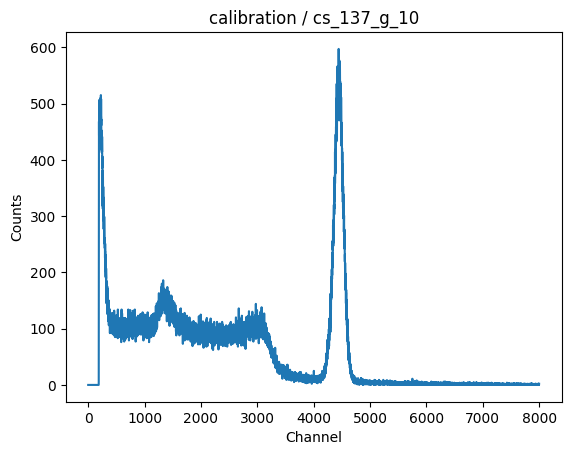

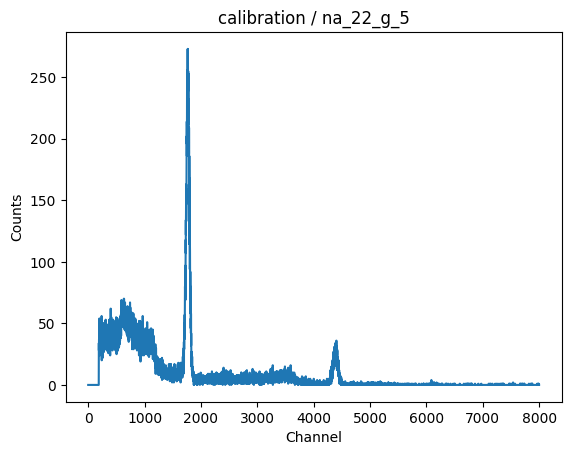

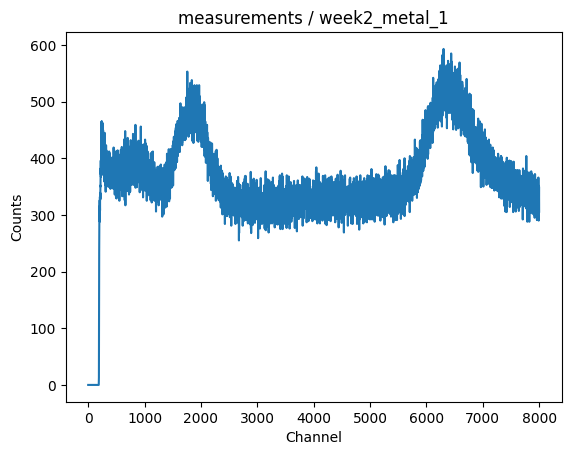

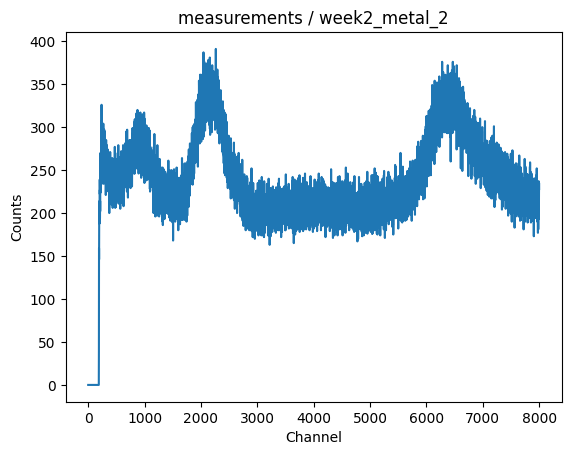

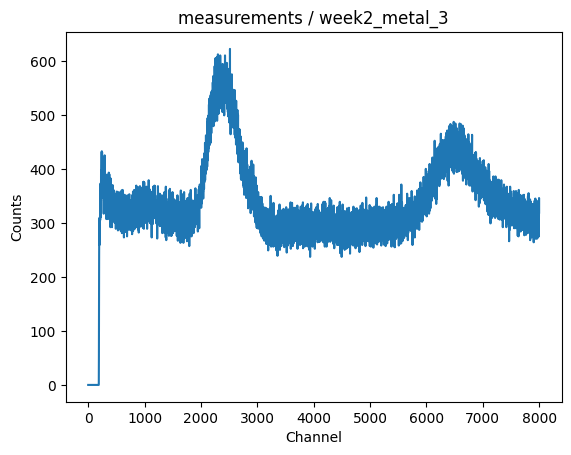

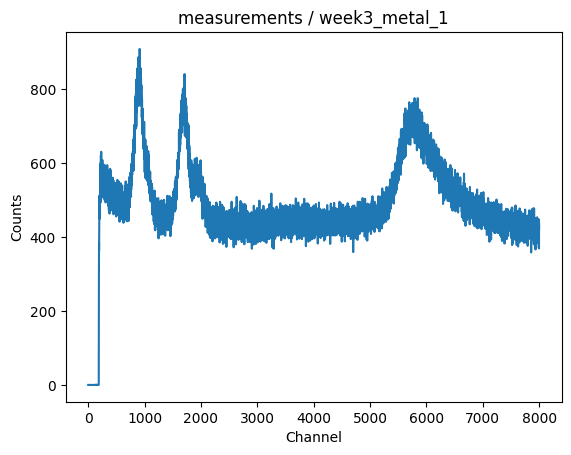

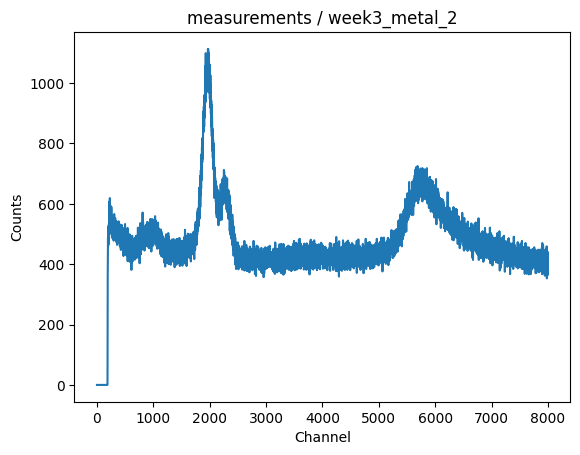

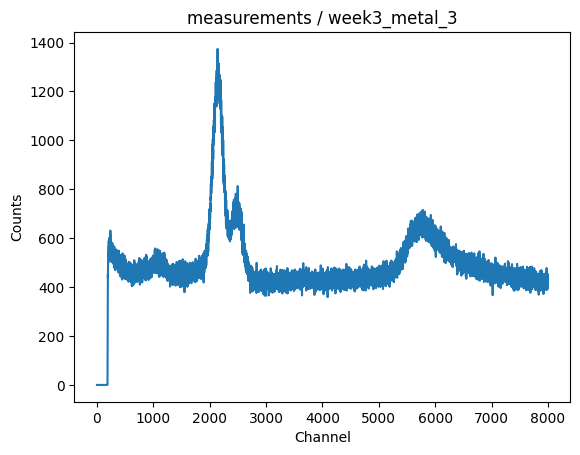

In [61]:
#PLOTS

for measurement_type, files in data.items():
    for scintillator, e in files.items():
        plot(measurement_type, scintillator)

In [62]:
#FUNCTIONS

def gauss(x, A, mu, sigma, c):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2)) + c

def find_peak(spectrum, measurement_type, smooth_sigma=10, prominence=50):
    spectrum = spectrum.astype(float)
    smooth = gaussian_filter1d(spectrum, smooth_sigma)
    n = len(spectrum)

    if measurement_type == "single_electron":
        return int(np.argmax(smooth)) #highest point overall (argmax also works if the peak is at the edge)

    if measurement_type == "source":
        start = n // 4 #only look in the last 3/4
        peaks, _ = find_peaks(smooth[start:], prominence=prominence)
        if len(peaks) == 0:
            raise ValueError("No peak found; lower the prominence")
        best = peaks[np.argmax(smooth[start:][peaks])]
        return int(best + start) #add the offset back
    
    raise ValueError("measurement_type must be 'source' or 'single_electron'")

In [63]:
#calibration linear fit: y = 11.591x + 9.0511